# 02 — Split train/test + EDA + features (emails) — v3

**Rappel v2** : `text_combined` est un texte déjà nettoyé en amont (minuscules, ponctuation supprimée, 0 % de majuscules / balises HTML). Les features `subject_uppercase_ratio`, `num_exclamation_marks`, `has_html_tags`, `num_urls_in_body`, `max_url_suspicion_score` n'ont donc rien à mesurer ici ; on garde `body_length`, `num_words`, `num_urgent_words` et on ajoute du **TF-IDF**. Les features structurelles complètes restent dans `email_features.py` pour un vrai email brut saisi plus tard.

**Ce qui change en v3**
1. **Split groupé** : on utilise `dup_group` (créé au notebook 01) pour qu'un groupe de quasi-doublons ne soit jamais coupé entre train et test.
2. **La matrice de test est construite ici**, avec exactement les mêmes transformations que le train (un seul chemin de code → pas de décalage train/test). Elle n'est *utilisée* qu'à la toute fin du notebook 03.
3. **`log1p` sur les 3 features numériques** : `body_length` monte à 4 millions, ce qui écrase tout le reste pour un modèle linéaire (la régression logistique de la v1 ne convergeait pas).
4. On sauvegarde aussi les **noms de colonnes**, les **groupes** (pour la validation croisée groupée) et le **vectorizer** dans `models/`.

Étapes :
1. Split train/test groupé et stratifié (≈ 80/20) + vérifications
2. Features numériques
3. EDA sur ces features
4. TF-IDF (fit sur le train uniquement) et mots discriminants
5. Fuites détectées : dates et marqueurs de source
6. Construire et sauvegarder X_train / X_test

In [1]:
import sys
sys.path.append("..")

import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold

from src.features.email_features import extract_features_batch

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 80)

RANDOM_STATE = 42
DATA = Path("../data/processed")
MODELS = Path("../models")
MODELS.mkdir(exist_ok=True)

## 1. Charger les données nettoyées + split groupé stratifié (≈ 80/20)

`StratifiedGroupKFold(n_splits=5)` : on prend le premier pli comme test (≈ 20 %). Il garde les groupes entiers d'un seul côté **et** respecte au mieux le ratio de classes.

In [2]:
df = pd.read_csv(DATA / "emails_clean.csv")
if "dup_group" not in df.columns:
    raise ValueError("Colonne dup_group absente : relancer d'abord le notebook 01 (v2).")

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(df, df["label"], groups=df["dup_group"]))
train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

print(f"Train: {len(train_df)} ({len(train_df)/len(df):.1%}) | Test: {len(test_df)} ({len(test_df)/len(df):.1%})")
print("Part de phishing  train / test :",
      round(train_df["label"].mean(), 3), "/", round(test_df["label"].mean(), 3))

Train: 62040 (80.0%) | Test: 15511 (20.0%)
Part de phishing  train / test : 0.495 / 0.495


Vérifications : aucun groupe, et a fortiori aucun texte, ne doit apparaître des deux côtés.

In [3]:
shared_groups = set(train_df["dup_group"]) & set(test_df["dup_group"])
shared_texts = set(train_df["text_combined"]) & set(test_df["text_combined"])
print("Groupes communs train/test :", len(shared_groups))
print("Textes identiques train/test :", len(shared_texts))
assert len(shared_groups) == 0 and len(shared_texts) == 0

Groupes communs train/test : 0
Textes identiques train/test : 0


## 2. Features numériques

On calcule les features via `email_features.py`, et on ne garde que celles qui ont une vraie variance sur ce dataset. Le sujet est déjà fusionné dans `text_combined` : on passe donc `subject=""` et `body=text_combined`.

In [4]:
NUMERIC_COLS = ["body_length", "num_words", "num_urgent_words"]


def numeric_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Features numériques brutes (avant log1p) pour un DataFrame avec text_combined."""
    tmp = frame[["text_combined"]].copy()
    tmp["subject"] = ""
    tmp["body"] = tmp["text_combined"]
    feats = extract_features_batch(tmp, subject_col="subject", body_col="body")
    return feats[NUMERIC_COLS].reset_index(drop=True)


train_numeric = numeric_features(train_df)
train_numeric["label"] = train_df["label"].values
train_numeric.describe()

,body_length,num_words,num_urgent_words,label
count,6.204000e+04,62040.000000,62040.000000,62040.000000
mean,1.249703e+03,159.685380,0.176999,0.494794
std,1.743460e+04,572.024388,1.017801,0.499977
min,3.000000e+00,1.000000,0.000000,0.000000
25%,2.680000e+02,38.000000,0.000000,0.000000
50%,5.410000e+02,76.000000,0.000000,0.000000
75%,1.209000e+03,168.000000,0.000000,1.000000
max,4.279526e+06,107710.000000,166.000000,1.000000


## 3. EDA sur ces features

`showfliers=False` pour ne pas écraser le graphe (quelques valeurs extrêmes, par exemple `num_urgent_words` jusqu'à 166 et `body_length` jusqu'à plusieurs millions). Ces extrêmes sont la raison du `log1p` appliqué plus bas.

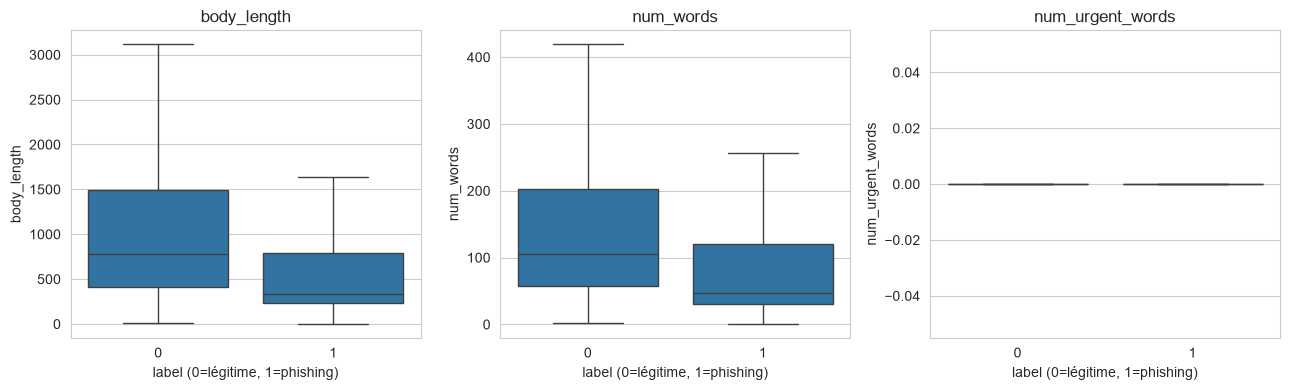

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, feat in zip(axes, NUMERIC_COLS):
    sns.boxplot(data=train_numeric, x="label", y=feat, ax=ax, showfliers=False)
    ax.set_title(feat)
    ax.set_xlabel("label (0=légitime, 1=phishing)")
plt.tight_layout()
plt.show()

In [11]:
print("Médiane par classe (0=légitime, 1=phishing) :")
print(train_numeric.groupby("label")[NUMERIC_COLS].median().to_string())
print()
print("Part d'emails avec au moins 1 mot d'urgence, par classe :")
print((train_numeric["num_urgent_words"] > 0).groupby(train_numeric["label"]).mean().round(3).to_string())

Médiane par classe (0=légitime, 1=phishing) :
       body_length  num_words  num_urgent_words
label                                          
0            779.0      106.0               0.0
1            334.0       47.0               0.0

Part d'emails avec au moins 1 mot d'urgence, par classe :
label
0    0.070
1    0.121


## 4. TF-IDF sur le texte

Fit **uniquement sur le train** : sinon le vocabulaire apprendrait des mots qui n'existent que dans le test (fuite de données). On commence par la version « naïve » pour voir ce qu'elle capte, puis on corrige à la section 5.

In [12]:
vectorizer_naive = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=5, stop_words="english")
X_naive = vectorizer_naive.fit_transform(train_df["text_combined"])
labels_train = train_df["label"].values
print("Shape TF-IDF naïf:", X_naive.shape)


def top_words(vec, X, labels, k=15):
    """Mots dont le score TF-IDF moyen diffère le plus entre phishing et légitime."""
    names = np.array(vec.get_feature_names_out())
    diff = (np.asarray(X[labels == 1].mean(axis=0)).ravel()
            - np.asarray(X[labels == 0].mean(axis=0)).ravel())
    return list(names[np.argsort(diff)[-k:]][::-1]), list(names[np.argsort(diff)[:k]])


phish_words, legit_words = top_words(vectorizer_naive, X_naive, labels_train)
print("Mots les plus associés au PHISHING:", phish_words)
print("Mots les plus associés au LÉGITIME:", legit_words)

Shape TF-IDF naïf: (62040, 5000)
Mots les plus associés au PHISHING: ['replica', 'aug 2008', 'aug', 'watches', '2008', 'money', '06 aug', 'wed 06', 'account', '07 aug', 'thu 07', '06', '0300', 'wed', 'life']
Mots les plus associés au LÉGITIME: ['enron', 'ect', 'wrote', 'list', 'pm', '2001', '2000', 'thanks', 'university', 'file', 'vince', 'hou', 'hou ect', 'subject', 'ect ect']


## 5. Fuites détectées

### 5a. Les dates trahissent la provenance du corpus

`aug 2008`, `06 aug`, `2008` ressortent côté phishing, `2000` côté légitime. Ce n'est pas un hasard : le corpus Enron (légitime) date de 2000-2001, CEAS_08 (une source phishing) de 2008. Un modèle apprendrait « année ≈ 2000 → légitime », un raccourci lié à la **date de collecte**, pas au contenu. On exclut les tokens numériques et les noms de mois/jours.

In [13]:
year_mask = train_df["text_combined"].str.contains(r"\b(?:2000|2001)\b", regex=True)
print(f"Emails contenant 2000 ou 2001 : {year_mask.sum()} "
      f"-> {1 - train_df.loc[year_mask, 'label'].mean():.1%} légitimes")

Emails contenant 2000 ou 2001 : 7630 -> 86.7% légitimes


In [14]:
MONTHS_DAYS = {
    "jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec",
    "mon", "tue", "wed", "thu", "fri", "sat", "sun",
}
stop_words_extended = list(TfidfVectorizer(stop_words="english").get_stop_words()) + list(MONTHS_DAYS)

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=5,
    stop_words=stop_words_extended,
    token_pattern=r"\b[a-z]{3,}\b",   # exclut les tokens purement numériques (dates, codes)
)
X_tfidf_train = vectorizer.fit_transform(train_df["text_combined"])
print("Shape TF-IDF train (corrigé):", X_tfidf_train.shape)

phish_words, legit_words = top_words(vectorizer, X_tfidf_train, labels_train)
print("Mots les plus associés au PHISHING (après correction):", phish_words)
print("Mots les plus associés au LÉGITIME (après correction):", legit_words)

Shape TF-IDF train (corrigé): (62040, 5000)
Mots les plus associés au PHISHING (après correction): ['replica', 'watches', 'money', 'account', 'love', 'life', 'health', 'click', 'replica watches', 'http', 'men', 'watch', 'rolex', 'bank', 'online']
Mots les plus associés au LÉGITIME (après correction): ['enron', 'ect', 'wrote', 'list', 'thanks', 'university', 'vince', 'file', 'hou', 'hou ect', 'subject', 'mailing list', 'ect ect', 'mailing', 'pythondev']


### 5b. Marqueurs de source restants

Après correction, il reste des mots comme `enron`, `ect`, `hou`, `vince`, `kaminski` (corpus Enron) ou `pythondev` (liste de diffusion Python). Ce sont des **noms de sources**, pas des indices de phishing : un modèle qui s'appuie dessus reconnaît le corpus d'origine, pas la menace. (Les newsletters CNN, qui dominaient ce tableau dans une première analyse, sont retirées du corpus dès le notebook 01.)

Le tableau ci-dessous liste les tokens fréquents (≥ 300 emails) presque *purs* (≥ 99 % ou ≤ 1 % de phishing). À lire avec discernement : `replica` ou `watches` sont de vrais signaux de spam, `enron` n'en est pas un. Le notebook 03 mesure ce que coûte le retrait d'une liste de marqueurs et décide d'après la validation croisée.

In [15]:
B = (X_tfidf_train > 0).tocsr()
doc_freq = np.asarray(B.sum(axis=0)).ravel()
phish_count = np.asarray(B[labels_train == 1].sum(axis=0)).ravel()
purity_df = pd.DataFrame({
    "token": vectorizer.get_feature_names_out(),
    "doc_freq": doc_freq,
    "part_phishing": (phish_count / np.maximum(doc_freq, 1)).round(3),
})
near_pure = purity_df[
    (purity_df["doc_freq"] >= 300)
    & ((purity_df["part_phishing"] >= 0.99) | (purity_df["part_phishing"] <= 0.01))
].sort_values("doc_freq", ascending=False)
print(f"{len(near_pure)} tokens fréquents quasi purs")
near_pure.head(30)

233 tokens fréquents quasi purs


,token,doc_freq,part_phishing
1454,enron,5502,0.000
2079,hou ect,2224,0.000
4837,watches,2121,0.991
1363,ect ect,2006,0.000
3057,opensuse,1757,0.000
1366,ect subject,1730,0.000
3531,python,1674,0.010
1455,enron com,1671,0.000
3532,pythondev,1656,0.000
3718,replica watches,1546,0.997


## 6. Construire et sauvegarder X_train / X_test

**Même transformation pour le train et le test** : `vectorizer.transform` (jamais `fit_transform` sur le test), puis les 3 features numériques passées en `log1p`. Les colonnes sont, dans l'ordre : 5000 colonnes TF-IDF, puis `body_length`, `num_words`, `num_urgent_words` (en `log1p`).

On sauvegarde : les matrices, les labels, les **groupes du train** (pour la validation croisée groupée), les **noms de colonnes**, le **vectorizer** (réutilisé à l'inférence dans l'API / la démo) et le test brut.

In [16]:
def to_model_numeric(raw_numeric: pd.DataFrame) -> sp.csr_matrix:
    """log1p des features numériques brutes -> bloc de colonnes de la matrice finale."""
    return sp.csr_matrix(np.log1p(raw_numeric[NUMERIC_COLS].values.astype(float)))


X_train = sp.hstack([X_tfidf_train, to_model_numeric(train_numeric)]).tocsr()
y_train = labels_train

test_numeric = numeric_features(test_df)
X_tfidf_test = vectorizer.transform(test_df["text_combined"])
X_test = sp.hstack([X_tfidf_test, to_model_numeric(test_numeric)]).tocsr()
y_test = test_df["label"].values

feature_names = list(vectorizer.get_feature_names_out()) + NUMERIC_COLS
assert X_train.shape[1] == X_test.shape[1] == len(feature_names)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Colonnes numériques (log1p), moyenne train :",
      np.round(np.asarray(X_train[:, -3:].mean(axis=0)).ravel(), 2))

X_train: (62040, 5003) | X_test: (15511, 5003)
Colonnes numériques (log1p), moyenne train : [6.38 4.42 0.09]


In [17]:
sp.save_npz(DATA / "emails_X_train.npz", X_train)
np.save(DATA / "emails_y_train.npy", y_train)
np.save(DATA / "emails_groups_train.npy", train_df["dup_group"].values)
sp.save_npz(DATA / "emails_X_test.npz", X_test)
np.save(DATA / "emails_y_test.npy", y_test)
test_df.to_csv(DATA / "emails_test_raw.csv", index=False)
with open(DATA / "emails_feature_names.json", "w", encoding="utf-8") as f:
    json.dump(feature_names, f, ensure_ascii=False)
joblib.dump(vectorizer, MODELS / "emails_tfidf_vectorizer.joblib")

print("Sauvegardé dans data/processed : emails_X_train.npz, emails_y_train.npy, emails_groups_train.npy,")
print("   emails_X_test.npz, emails_y_test.npy, emails_test_raw.csv, emails_feature_names.json")
print("Sauvegardé dans models : emails_tfidf_vectorizer.joblib")

Sauvegardé dans data/processed : emails_X_train.npz, emails_y_train.npy, emails_groups_train.npy,
   emails_X_test.npz, emails_y_test.npy, emails_test_raw.csv, emails_feature_names.json
Sauvegardé dans models : emails_tfidf_vectorizer.joblib


**À retenir pour l'inférence** (API / démo) : pour un email saisi en direct, il faut refaire exactement la même chaîne : `vectorizer.transform(texte)` → features numériques via `email_features.py` → `log1p` → `hstack` → sélection de colonnes du modèle (voir `keep_cols` dans le notebook 03).